In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree 

data = {
    "buying": ["high", "low", "med", "low", "high", "med"],
    "maint": ["high", "low", "med", "low", "high", "med"],
    "doors": ["2", "4", "4", "5more", "2", "4"],
    "persons": ["2", "4", "more", "more", "2", "4"],
    "lug_boot": ["small", "big", "med", "big", "small", "med"],
    "safety": ["low", "high", "high", "med", "low", "high"],
    "class": ["unacc", "good", "vgood", "good", "unacc", "acc"]
}

df = pd.DataFrame(data)

print("CAR EVALUATION DATASET")
print(df) 

CAR EVALUATION DATASET
  buying maint  doors persons lug_boot safety  class
0   high  high      2       2    small    low  unacc
1    low   low      4       4      big   high   good
2    med   med      4    more      med   high  vgood
3    low   low  5more    more      big    med   good
4   high  high      2       2    small    low  unacc
5    med   med      4       4      med   high    acc



CAR EVALUATION RESULT
Predicted Car Category: good


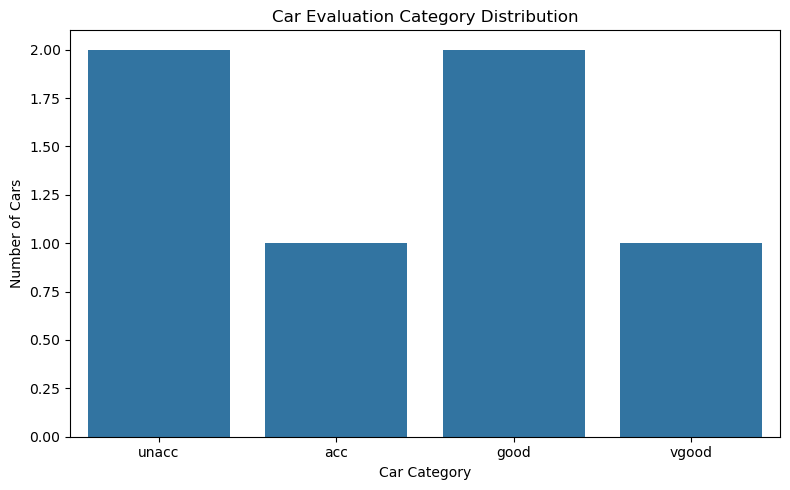

In [4]:
X = pd.get_dummies(df.drop("class", axis=1))
y = df["class"] 

model = DecisionTreeClassifier(random_state=42)
model.fit(X, y)  

new_car = pd.DataFrame([{
    "buying": "low",
    "maint": "low",
    "doors": "4",
    "persons": "4",
    "lug_boot": "big",
    "safety": "high"
}])

new_car = pd.get_dummies(new_car)
new_car = new_car.reindex(columns=X.columns, fill_value=0)

prediction = model.predict(new_car)

print("\nCAR EVALUATION RESULT")
print("Predicted Car Category:", prediction[0]) 

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="class", order=["unacc", "acc", "good", "vgood"])

plt.title("Car Evaluation Category Distribution")
plt.xlabel("Car Category")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show() 

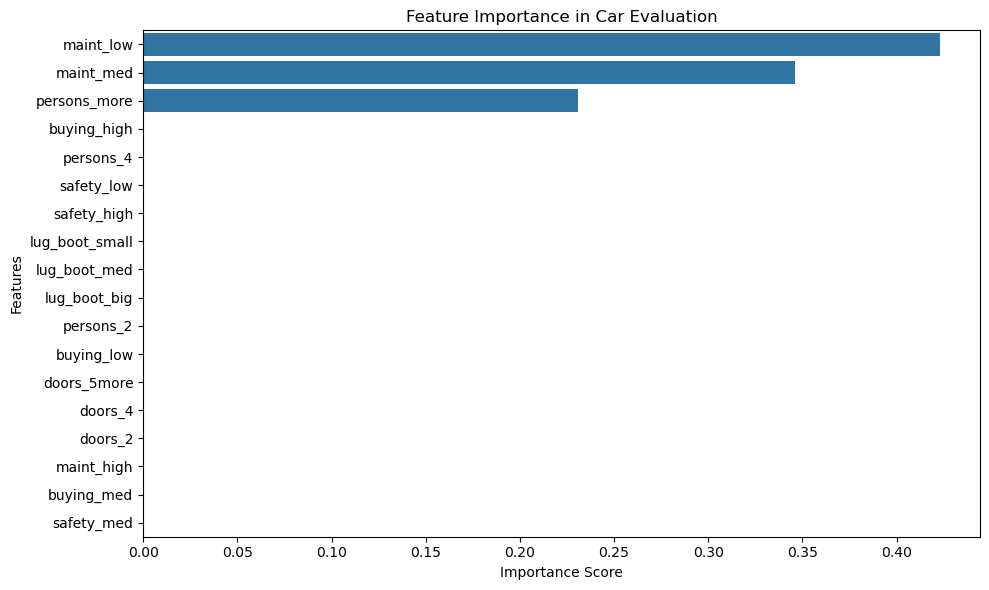

In [5]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Car Evaluation")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show() 

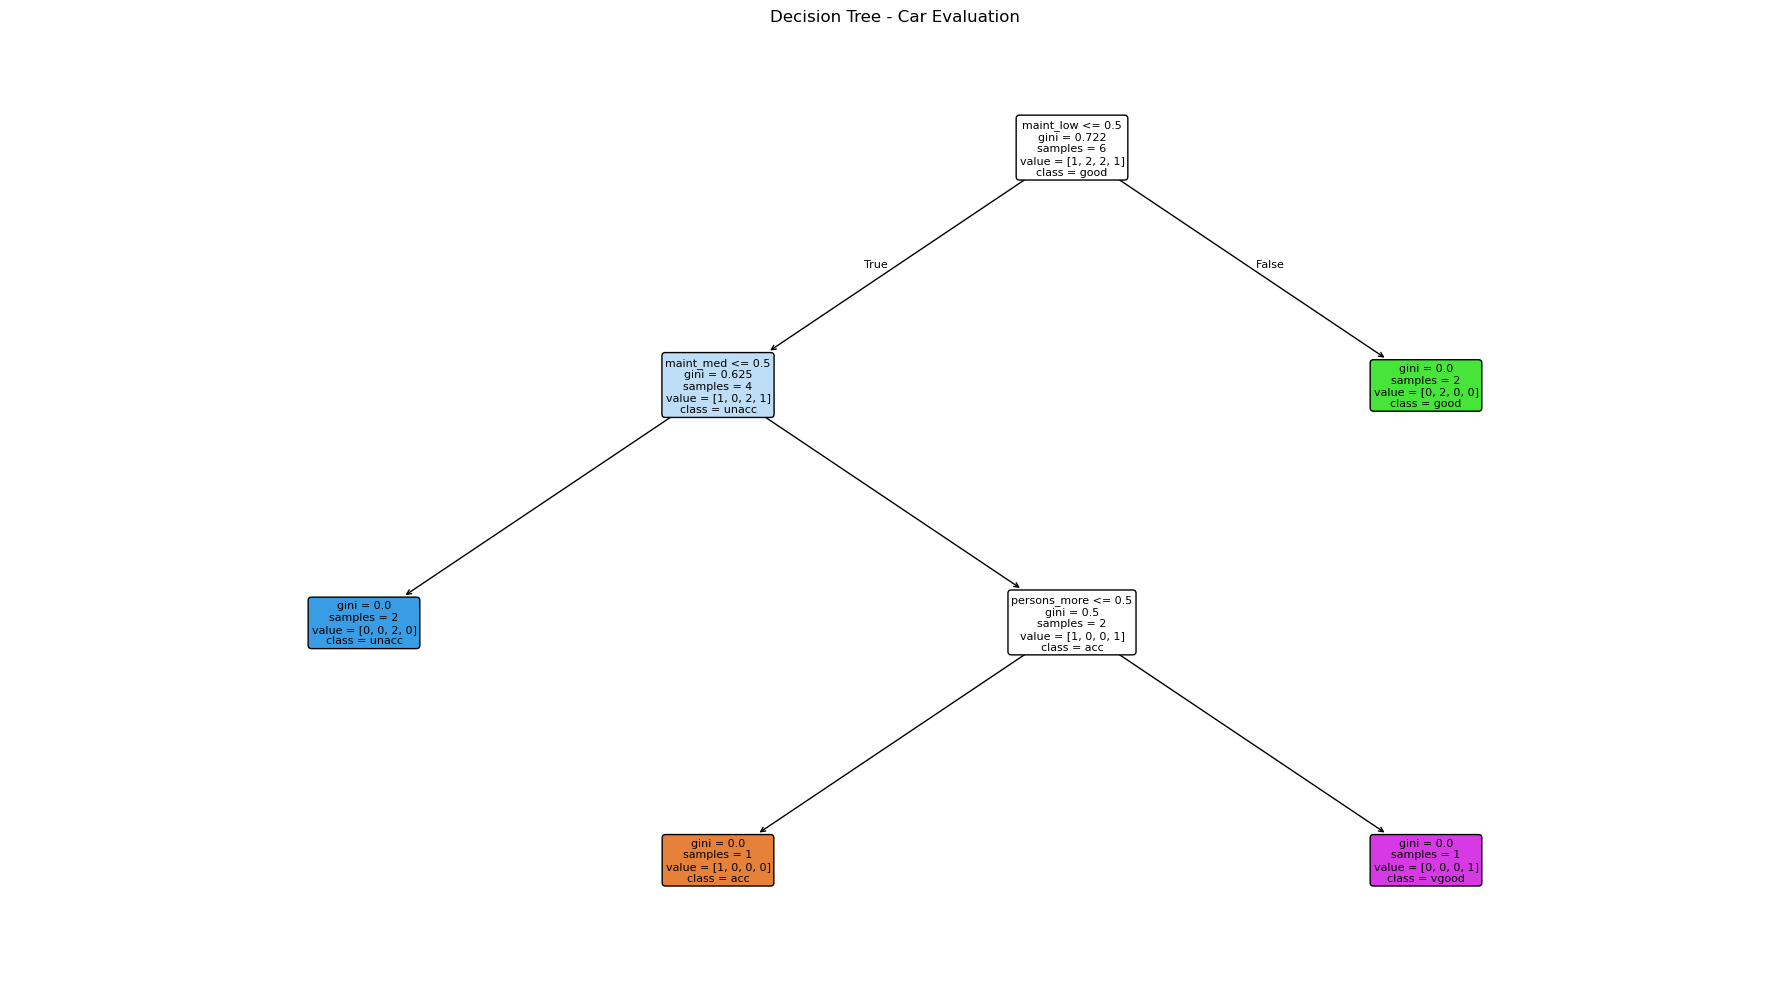

In [6]:
plt.figure(figsize=(18, 10))

plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=list(model.classes_),
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree - Car Evaluation")
plt.tight_layout()
plt.show() 

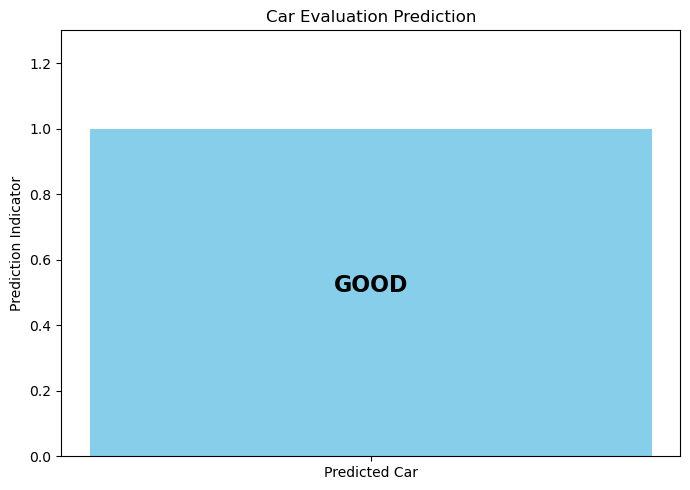


All Visualizations Completed Successfully!


In [7]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Predicted Car"],
    [1],
    color="skyblue"
)

plt.title("Car Evaluation Prediction")
plt.ylabel("Prediction Indicator")

plt.text(
    0, 0.5,
    prediction[0].upper(),
    ha="center",
    fontsize=16,
    fontweight="bold"
)

plt.ylim(0, 1.3)
plt.tight_layout()
plt.show()

print("\nAll Visualizations Completed Successfully!") 